In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.decomposition import PCA
print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
data = pd.DataFrame({
    "Study_Hours":[2,4,5,7,8,10],
    "Attendence_Percent":[50,60,65,75,85,95],
    "Assingnment_Score":[35,45,55,65,80,95],
    "Final_Marks":[38,48,56,68,82,94]
})
display(data)

,Study_Hours,Attendence_Percent,Assingnment_Score,Final_Marks
0,2,50,35,38
1,4,60,45,48
2,5,65,55,56
3,7,75,65,68
4,8,85,80,82
5,10,95,95,94


In [9]:
features = data[["Study_Hours", "Attendence_Percent", "Assingnment_Score"]]
print("Minimum values")
print(features.min())
print("\nMaximum values:")
print(features.max())

Minimum values
Study_Hours            2
Attendence_Percent    50
Assingnment_Score     35
dtype: int64

Maximum values:
Study_Hours           10
Attendence_Percent    95
Assingnment_Score     95
dtype: int64


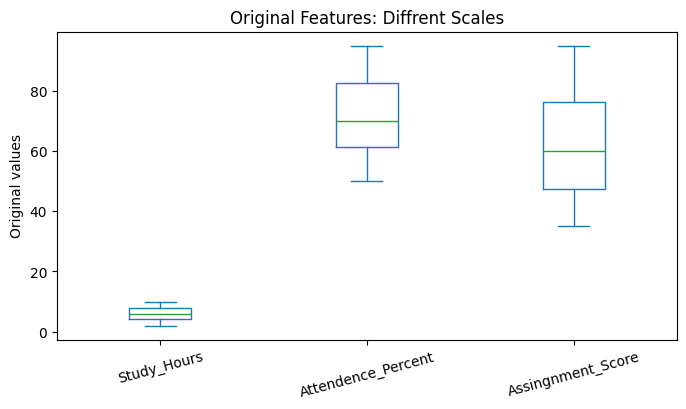

In [10]:
features.plot(kind="box" , figsize=(8,4))
plt.title("Original Features: Diffrent Scales")
plt.ylabel("Original values")
plt.xticks(rotation=15)
plt.show()

In [12]:
normalizer = MinMaxScaler()
normalized_array = normalizer.fit_transform(features)
normalized_df = pd.DataFrame(
    normalized_array,
    columns=features.columns,
    index=features.index
)
display(normalized_df,round(3))


,Study_Hours,Attendence_Percent,Assingnment_Score
0,0.000,0.000000,0.000000
1,0.250,0.222222,0.166667
2,0.375,0.333333,0.333333
3,0.625,0.555556,0.500000
4,0.750,0.777778,0.750000
5,1.000,1.000000,1.000000


3

In [13]:
print("Minimum after normaliation:")
print(normalized_df.min())
print("\nMaximum after normalizaion:")
print(normalized_df.max())

Minimum after normaliation:
Study_Hours           0.0
Attendence_Percent    0.0
Assingnment_Score     0.0
dtype: float64

Maximum after normalizaion:
Study_Hours           1.0
Attendence_Percent    1.0
Assingnment_Score     1.0
dtype: float64


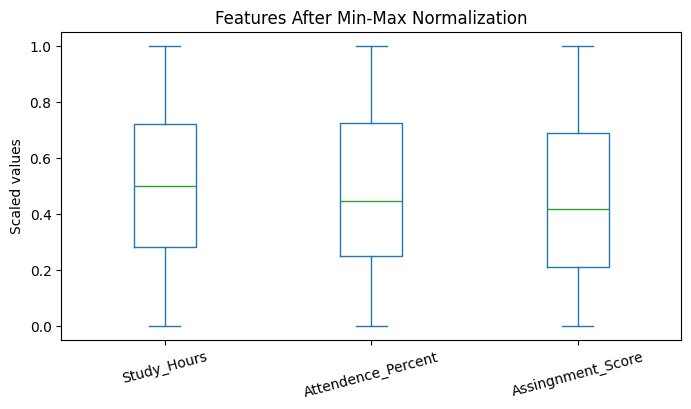

In [15]:
normalized_df.plot(kind="box" , figsize=(8,4))
plt.title("Features After Min-Max Normalization")
plt.ylabel("Scaled values")
plt.xticks(rotation=15)
plt.show()

In [2]:
standardizer = StandardScaler()
standardized_array = standardizer.fit_transform(features)
standardized_df = pd.DataFrame(
    standardized_array,
    columns=features.columns,
    index=features.index
)
display(standardized_df.round(3))

NameError: name 'StandardScaler' is not defined

In [17]:
print("Minimum after standardization:")
print(standardized_df.mean(),round(6))
print("\Standard deviations after standardization:")
print(standardized_df.std(ddof=0),round(6))

Minimum after standardization:
Study_Hours           0.500000
Attendence_Percent    0.481481
Assingnment_Score     0.458333
dtype: float64 6
\Standard deviations after standardization:
Study_Hours           0.330719
Attendence_Percent    0.337423
Assingnment_Score     0.339355
dtype: float64 6


<>:3: SyntaxWarning: invalid escape sequence '\S'
<>:3: SyntaxWarning: invalid escape sequence '\S'
/tmp/ipykernel_4816/1851806339.py:3: SyntaxWarning: invalid escape sequence '\S'
  print("\Standard deviations after standardization:")


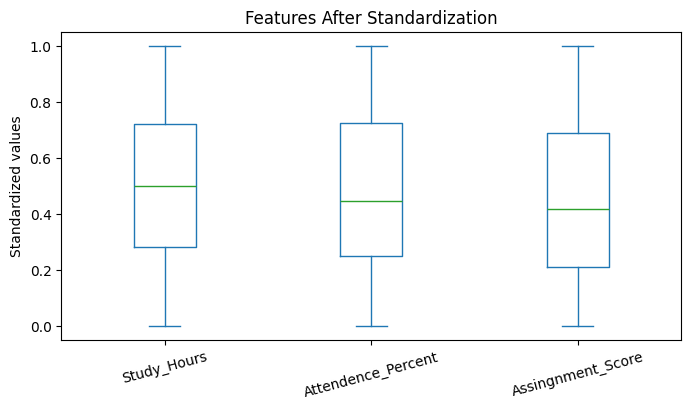

In [18]:
standardized_df.plot(kind="box" , figsize=(8,4))
plt.title("Features After Standardization")
plt.ylabel("Standardized values")
plt.xticks(rotation=15)
plt.show()

In [20]:
scaled_features = StandardScaler().fit_transform(features)
pca = PCA(n_components=2)
pca_array = pca.fit_transform(scaled_features)
pca_df = pd.DataFrame(
    pca_array,
    columns=["PC1", "PC2"],
    index=features.index
)
display(pca_df.round(3))

,PC1,PC2
0,-2.476,-0.115
1,-1.376,0.069
2,-0.684,-0.001
3,0.416,0.182
4,1.440,-0.078
5,2.682,-0.057


In [22]:
variance_ratios = pca.explained_variance_ratio_
for component, ratio in zip(["PC1", "PC2"], variance_ratios):
    print(f"{component} explains {ratio:.2%} of the variance")

total_retained = variance_ratios.sum()
print(f"\nTotal variance retained by 2 components: {total_retained:.2%}")

PC1 explains 99.62% of the variance
PC2 explains 0.34% of the variance

Total variance retained by 2 components: 99.96%


In [4]:
component_names=["PC1","PC2"]
cumulative_variance=variance_ratios.cumsum()
plt.figure(figsize=(7,4))
plt.bar(component_names,variance_ratios)
plt.plot(component_names,cumulative_variance,marker="o")
plt.ylim(0,1.05)
plt.ylabel("Proportion of variance")
plt.title("PCA Explained and Cumulative Variance")
plt.legend(["Cumulative variance","Individual component"])
plt.show()

NameError: name 'variance_ratios' is not defined